## Generating the datasets' metadata and actual relations

The cell below generates `total_datasets_to_be_generated` datasets. No input data is generated yet. For each dataset, it randomly picks:

- **dimension**: the number of features (1 to 9)
- **noise intensity**: a value between 0 (low noise) and 1 (high noise), not applied yet
- **relation**: `linear` or `non-linear`, using the probabilities in `relation_probabilities`

Then it builds the **actual relation**, the function the regressor will later try to estimate:

- **linear**: $y = w_0 + w_1 x_1 + \dots + w_d x_d$
- **non-linear** (the generalized linear form from the lecture): $y = w_0 + w_1 \phi_1(x_1) + \dots + w_d \phi_d(x_d)$, where each feature gets its own function $\phi_j$, picked randomly from `non_linear_functions` (a polynomial of degree 2 to 10, sin, cos, log, sqrt, abs, tanh, sigmoid or gaussian)

The weights $w_0, \dots, w_d$ are picked randomly between -10 and 10. Each dataset is stored in `datasets` as a tuple:
`(dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula)`, where `formula` is a readable version of the relation. `samples_size` is left as `None` here; it is set in the next cell. Finally, the cell prints every dataset's metadata.

In [ ]:
import numpy as np
from numpy.random import PCG64

total_datasets_to_be_generated = 5

rng = np.random.Generator(PCG64())

relation_types = ("linear", "non-linear")
relation_probabilities = [0, 1]  # 0.5, 0.5

non_linear_functions = {
    "polynomial": lambda x, degree: x ** degree,
    "sin": lambda x: np.sin(x),
    "cos": lambda x: np.cos(x),
    "log": lambda x: np.log(np.abs(x) + 1),
    "sqrt": lambda x: np.sqrt(np.abs(x)),
    "abs": lambda x: np.abs(x),
    "tanh": lambda x: np.tanh(x),
    "sigmoid": lambda x: 1 / (1 + np.exp(-x)),
    "gaussian": lambda x: np.exp(-x ** 2 / 2),
}

datasets = []

for _ in range(total_datasets_to_be_generated):

    # to change dimension, noise intensity and relation type, change the following lines
    dimension = int(9 * rng.random(size=None) + 1)
    # dimension = 1

    noise_intensity = rng.random(size=None)
    # noise_intensity = 0.03

    relation = rng.choice(relation_types, p=relation_probabilities)

    actual_relation = None

    if relation == "linear":
        weights = rng.uniform(-10, 10, size=dimension + 1)
        actual_relation = lambda X, weights=weights: weights[0] + X @ weights[1:]
        formula = f"y = {weights[0]:.2f}"
        for j in range(dimension):
            formula += f" + ({weights[j + 1]:.2f})·x{j + 1}"
    else:
        weights = rng.uniform(-10, 10, size=dimension + 1)
        feature_functions = []
        formula = f"y = {weights[0]:.2f}"
        for j in range(dimension):
            name = rng.choice(list(non_linear_functions))
            if name == "polynomial":
                degree = int(rng.integers(2, 11))
                feature_functions.append(lambda x, degree=degree: non_linear_functions["polynomial"](x, degree))
                formula += f" + ({weights[j + 1]:.2f})·x{j + 1}^{degree}"
            else:
                feature_functions.append(non_linear_functions[name])
                formula += f" + ({weights[j + 1]:.2f})·{name}(x{j + 1})"
        actual_relation = lambda X, weights=weights, feature_functions=feature_functions, dimension=dimension: weights[0] + sum(weights[j + 1] * feature_functions[j](X[:, j]) for j in range(dimension))

    datasets.append((dimension, None, noise_intensity, relation, weights, actual_relation, formula))

for i, (dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula) in enumerate(datasets):
    print(f"dataset {i + 1}:")
    print(f"  dimension:       {dimension}")
    print(f"  noise intensity: {noise_intensity:.2f}")
    print(f"  relation:        {relation}")
    print(f"  weights:         {weights}")
    print(f"  formula:         {formula}")

dataset 1:
  dimension:       1
  noise intensity: 0.03
  relation:        non-linear
  weights:         [-2.63364344  1.71225018]
  formula:         y = -2.63 + (1.71)·cos(x1)


## Generating the sample data

The cell below first sets each dataset's **samples size** (the number of samples, 100 to 4999 when randomized), now that the rest of its metadata is known, and stores it in the dataset's tuple. Then it uses the metadata to generate the samples:

- **inputs** `X`: a `samples_size × dimension` matrix, each value picked uniformly between -1000 and 1000
- **clean outputs** `y_clean`: the actual relation applied to the inputs, $f(\mathbf{x})$
- **noisy outputs** `y`: the clean outputs plus Gaussian noise, $y = f(\mathbf{x}) + \varepsilon$, where $\varepsilon \sim \mathcal{N}(0, \sigma^2)$

The noise's standard deviation is scaled to each dataset's outputs: $\sigma = \text{noise\_intensity} \times \text{std}(y_{clean})$. This way `noise_intensity` means the same in every dataset, whatever the size of its outputs: 0 means no noise, 0.5 means noise about half as large as the spread of the outputs, and 1 means noise as large as the spread itself.

### Why the noise is random and not a constant

Adding the same constant $c$ to every target value is not real noise. It only shifts the whole relation: $y = f(\mathbf{x}) + c$, which is the same as changing the bias from $w_0$ to $w_0 + c$. That is a new, perfectly regular pattern, so the regressor would learn it exactly and none of it would count as error. Real noise is different for each sample, unpredictable from the input, and averages out to zero. That's why a separate random value $\varepsilon$ is drawn for every sample.

The samples are stored in `samples` as `(X, y)` tuples, in the same order as `datasets`, so `samples[i]` belongs to `datasets[i]`. They are also added to each dataset's tuple as an 8th field, so every tuple in `datasets` becomes:
`(dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y))`.

Finally, the cell prints the first 15 patterns of each dataset and, for every 1-dimensional dataset, draws a scatter plot of its samples ($x_1$ against $y$). Only 1-dimensional datasets are plotted, because data with more features can't be drawn on a 2D plot; the other datasets are only printed.

dataset 1:
  x = [   560.19]  ->  y = -1.70
  x = [  -403.22]  ->  y = -1.89
  x = [   768.46]  ->  y = -3.21
  x = [   876.45]  ->  y = -4.34
  x = [   536.52]  ->  y = -3.96
  x = [   496.81]  ->  y = -1.07
  x = [   119.78]  ->  y = -1.05
  x = [   313.54]  ->  y = -1.26
  x = [  -450.61]  ->  y = -3.00
  x = [   270.25]  ->  y = -0.94
  x = [  -837.05]  ->  y = -2.27
  x = [   240.13]  ->  y = -2.32
  x = [   103.43]  ->  y = -4.28
  x = [   784.91]  ->  y = -1.11
  x = [  -330.55]  ->  y = -3.99


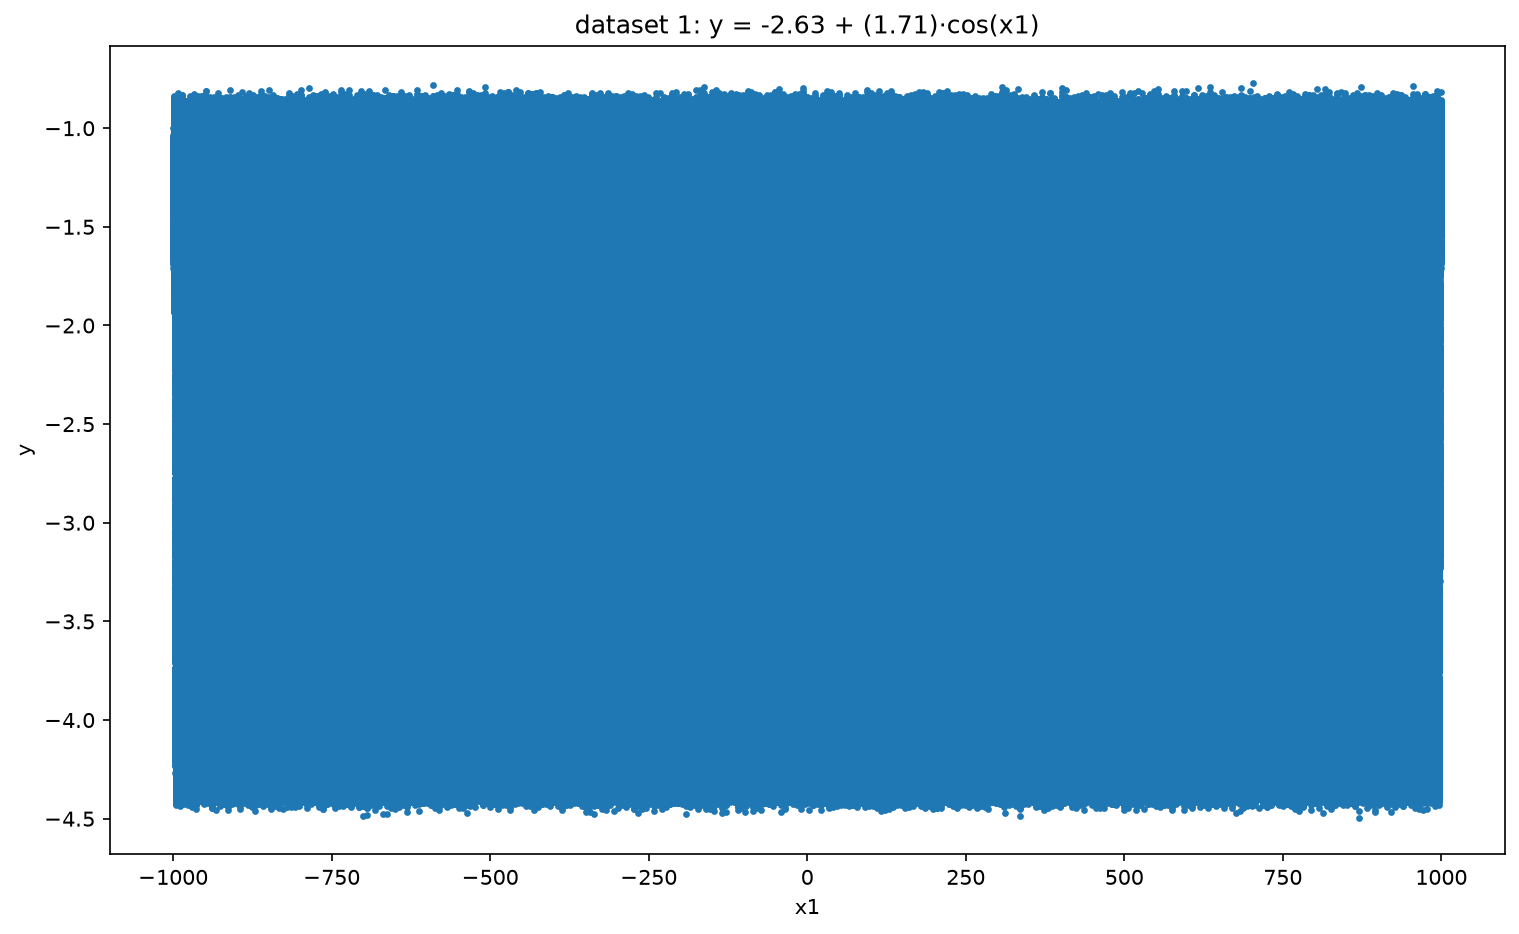

In [ ]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 7)
plt.rcParams["figure.dpi"] = 150

samples = []

for i in range(len(datasets)):
    dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula = datasets[i][:7]

    # to change samples size, change the following lines
    samples_size = int(4900 * rng.random(size=None) + 100)
    # samples_size = 1000

    X = rng.uniform(-1000, 1000, size=(samples_size, dimension))
    y_clean = actual_relation(X)
    noise_std = noise_intensity * np.std(y_clean)
    y = y_clean + rng.normal(0, noise_std, size=samples_size)
    samples.append((X, y))
    datasets[i] = (dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y))

for i, (X, y) in enumerate(samples):
    print(f"dataset {i + 1}:")
    for k in range(15):
        features = ", ".join(f"{value:9.2f}" for value in X[k])
        print(f"  x = [{features}]  ->  y = {y[k]:.2f}")

one_dimensional_found = False

for i, (dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y)) in enumerate(datasets):
    if dimension == 1:
        one_dimensional_found = True
        plt.figure()
        plt.scatter(X[:, 0], y, s=5)
        plt.title(f"dataset {i + 1}: {formula}")
        plt.xlabel("x1")
        plt.ylabel("y")
        plt.show()

if not one_dimensional_found:
    print("there are no 1-dimensional datasets to visualize")

## 10-fold cross validation and linear regression

The cell below finds a linear regressor for every dataset and measures its error with $k$-fold cross validation ($k = 10$):

1. A column of ones is added in front of `X` (`X_with_bias`) so the bias $w_0$ is learned as well.
2. The samples are divided into 10 folds. In each of the 10 iterations, one fold is the **test** data and the other 9 are the **training** data, so every sample is used for testing exactly once.
3. On the training data, the regressor is found with the least squares (normal equation) method from the lecture: $\mathbf{w} = (X^T X)^{-1} X^T \mathbf{y}$.
4. On the test data, the regressor's error is measured. Every test sample has the same weight $\frac{1}{n}$:
   - $RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (\hat{y}_i - y_i)^2}$
   - $MAE = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i|$
   - $MAPE = \frac{1}{n}\sum_{i=1}^{n} \left|\frac{y_i - \hat{y}_i}{y_i}\right| \cdot 100\%$. It becomes very large when some targets are close to 0, because it divides by each $y_i$.
   - $R^2 = 1 - \frac{\sum_{i}(y_i - \hat{y}_i)^2}{\sum_{i}(y_i - \bar{y})^2}$, the coefficient of determination: 1 is a perfect fit, 0 is no better than always predicting the mean $\bar{y}$
5. Each error is averaged over the 10 folds: $E = \frac{1}{10}\sum_{i=1}^{10} E_i$.

The results are stored in `cross_validation_results`, in the same order as `datasets`. Each entry is `(fold_results, average_rmse, average_mae, average_mape, average_r2)`, where `fold_results` holds `(w, rmse, mae, mape, r2)` for each fold.

For every dataset, the cell prints each fold's errors with its estimated regressor, then the averages. Only 1-dimensional datasets are plotted: for them, the cell also draws the samples together with the 10 regression lines. Datasets with more dimensions are only printed.

dataset 1: y = -2.63 + (1.71)·cos(x1)
samples size: 1000000, noise intensity: 0.03
    fold           RMSE            MAE       MAPE (%)         R²   estimated regressor
       1         1.2130         1.0920        59.5550     0.0000   y = -2.6329 + (-0.0000)·x1
       2         1.2097         1.0884        59.1482    -0.0000   y = -2.6323 + (-0.0000)·x1
       3         1.2119         1.0912        59.2735    -0.0000   y = -2.6325 + (-0.0000)·x1
       4         1.2115         1.0904        59.4888    -0.0000   y = -2.6333 + (-0.0000)·x1
       5         1.2111         1.0901        59.6135    -0.0000   y = -2.6335 + (-0.0000)·x1
       6         1.2115         1.0905        59.2926    -0.0000   y = -2.6325 + (-0.0000)·x1
       7         1.2114         1.0897        59.3317    -0.0000   y = -2.6325 + (-0.0000)·x1
       8         1.2126         1.0923        59.5439    -0.0000   y = -2.6326 + (-0.0000)·x1
       9         1.2117         1.0907        59.5904    -0.0000   y = -2.6331

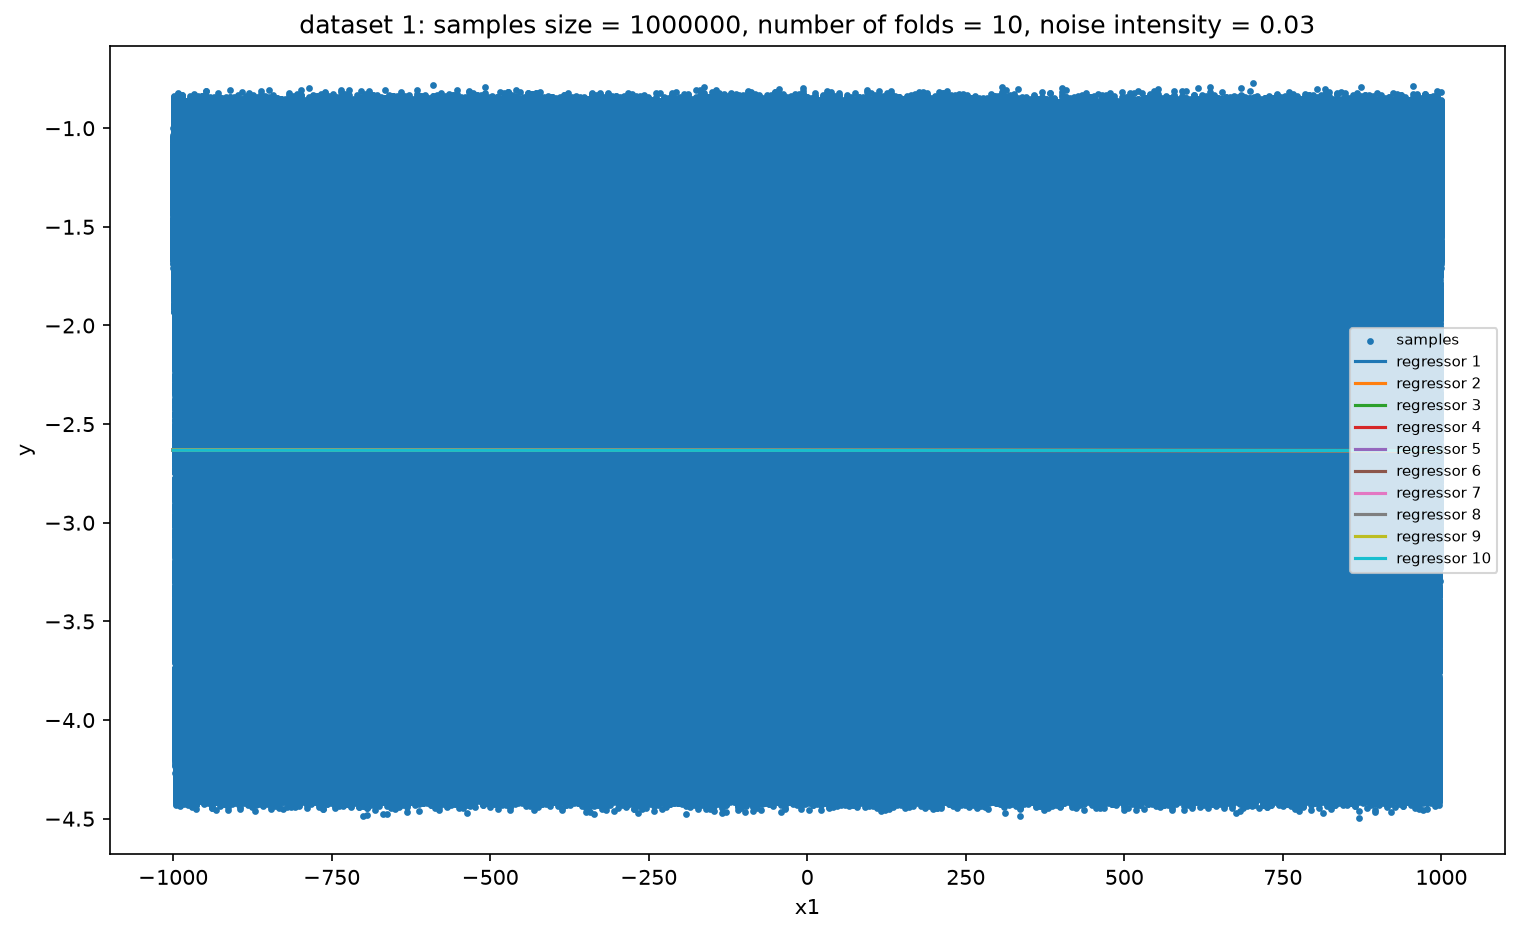

In [184]:
k = 10

cross_validation_results = []

for dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y) in datasets:
    X_with_bias = np.hstack((np.ones((samples_size, 1)), X))
    folds = np.array_split(np.arange(samples_size), k)

    fold_results = []

    for f in range(k):
        test_indices = folds[f]
        train_indices = np.concatenate([folds[m] for m in range(k) if m != f])

        X_train, y_train = X_with_bias[train_indices], y[train_indices]
        X_test, y_test = X_with_bias[test_indices], y[test_indices]

        # training the linear regression model using the normal equation
        w = np.linalg.inv(X_train.T @ X_train) @ X_train.T @ y_train

        # training done, now we get to testing
        y_predicted = X_test @ w
        rmse = np.sqrt(np.mean((y_predicted - y_test) ** 2))
        mae = np.mean(np.abs(y_test - y_predicted))
        mape = np.mean(np.abs((y_test - y_predicted) / y_test)) * 100
        r2 = 1 - np.sum((y_test - y_predicted) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2)

        fold_results.append((w, rmse, mae, mape, r2))

    average_rmse = np.mean([rmse for w, rmse, mae, mape, r2 in fold_results])
    average_mae = np.mean([mae for w, rmse, mae, mape, r2 in fold_results])
    average_mape = np.mean([mape for w, rmse, mae, mape, r2 in fold_results])
    average_r2 = np.mean([r2 for w, rmse, mae, mape, r2 in fold_results])

    cross_validation_results.append((fold_results, average_rmse, average_mae, average_mape, average_r2))

for i in range(len(datasets)):
    dimension, samples_size, noise_intensity, relation, weights, actual_relation, formula, (X, y) = datasets[i]
    fold_results, average_rmse, average_mae, average_mape, average_r2 = cross_validation_results[i]

    equations = []
    for w, rmse, mae, mape, r2 in fold_results:
        equation = f"y = {w[0]:.4f}"
        for j in range(dimension):
            equation += f" + ({w[j + 1]:.4f})·x{j + 1}"
        equations.append(equation)

    print(f"dataset {i + 1}: {formula}")
    print(f"samples size: {samples_size}, noise intensity: {noise_intensity:.2f}")
    print(f"{'fold':>8} {'RMSE':>14} {'MAE':>14} {'MAPE (%)':>14} {'R²':>10}   estimated regressor")
    for f, (w, rmse, mae, mape, r2) in enumerate(fold_results):
        print(f"{f + 1:>8} {rmse:>14.4f} {mae:>14.4f} {mape:>14.4f} {r2:>10.4f}   {equations[f]}")
    print(f"{'average':>8} {average_rmse:>14.4f} {average_mae:>14.4f} {average_mape:>14.4f} {average_r2:>10.4f}")

    if dimension == 1:
        plt.figure()
        plt.scatter(X[:, 0], y, s=5, label="samples")
        x_line = np.array([-1000, 1000])
        for f, (w, rmse, mae, mape, r2) in enumerate(fold_results):
            plt.plot(x_line, w[0] + w[1] * x_line, label=f"regressor {f + 1}")
        plt.title(f"dataset {i + 1}: samples size = {samples_size}, number of folds = {k}, noise intensity = {noise_intensity:.2f}")
        plt.xlabel("x1")
        plt.ylabel("y")
        plt.legend(fontsize=7)
        plt.show()

    print()